In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path
from datetime import timedelta, timezone

src_path = Path().resolve().parents[1] / 'src'
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))


from sciezka_projektu import get_project_root

PROJECT_ROOT = get_project_root()

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "Rybnik"

df_r_pz1 = pd.read_parquet(DATA_PATH / "pz1-2024.parquet")

df_rs_opady = pd.read_parquet(DATA_PATH / "suma_opadow.parquet")



def fix_tz_local(df, time_col="Data_czas"):
    res = df.copy()
    if time_col in res.columns:
        res[time_col] = pd.to_datetime(res[time_col])
        res = res.set_index(time_col)

    # Kluczowe: sortowanie i usunięcie zduplikowanych timestampów przed tz_localize
    res = res.sort_index()
    res = res[~res.index.duplicated(keep="first")]

    if res.index.tz is None:
        res.index = res.index.tz_localize(
            "Europe/Warsaw",
            ambiguous="NaT",
            nonexistent="shift_forward",
        )

    res = res[res.index.notna()]
    res.index = res.index.tz_convert(timezone(timedelta(hours=1)))
    return res



PROJECT_ROOT = get_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "Rybnik"

df_r_pz1 = pd.read_parquet(DATA_PATH / "pz1-2024.parquet")
df_r_opady = pd.read_parquet(DATA_PATH / "suma_opadow.parquet")

# 1. Strefa czasowa i czyszczenie PZ1
df = fix_tz_local(df_r_pz1)
df = df.rename(columns={"Wartosc": "ilosc"})

df["ilosc"] = pd.to_numeric(
    df["ilosc"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce",
)
df = df[df["ilosc"].notna()].sort_index()

# 2. Strefa czasowa i agregacja opadów
df_r_opady = fix_tz_local(df_r_opady)
df_r_opady = df_r_opady.groupby(level=0).agg({"suma_opadu_mm": "sum"})

# 3. Godzinowy przyrost przepływu z licznika narastającego
hourly = df["ilosc"].resample("1h").last()
df_1h = pd.DataFrame({"przepompowano": hourly.diff()})
df_1h.loc[df_1h["przepompowano"] < 0, "przepompowano"] = np.nan

df_1h

,przepompowano
Data_czas,
2024-03-05 19:00:00+01:00,NaN
2024-03-05 20:00:00+01:00,0.0
2024-03-05 21:00:00+01:00,0.0
2024-03-05 22:00:00+01:00,0.0
2024-03-05 23:00:00+01:00,0.0
...,...
2024-12-30 20:00:00+01:00,159.5
2024-12-30 21:00:00+01:00,179.1
2024-12-30 22:00:00+01:00,174.2


In [2]:
%load_ext autoreload
%autoreload 2

from przepompowanie_rybnik_dane import przygotuj_dane_przepompowanie_pz1

X,y = przygotuj_dane_przepompowanie_pz1()

In [3]:
%load_ext autoreload
%autoreload 2

train_end = int(len(X) * 0.7)

X_train = X.iloc[:train_end]
X_test = X.iloc[train_end:]

y_train = y.iloc[:train_end]
y_test = y.iloc[train_end:]

#print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
#print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
#print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
# CATBOOST
from catboost import CatBoostRegressor

cb_median = CatBoostRegressor(
    loss_function = "MAE",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_median.fit(X_train, y_train)

cb_q97 = CatBoostRegressor(
    loss_function = "Quantile:alpha=0.97",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_q97.fit(X_train, y_train)

y_pred_val = cb_median.predict(X_test)
q_val = cb_q97.predict(X_test)

Godziny ponad normę: 30 z 2055


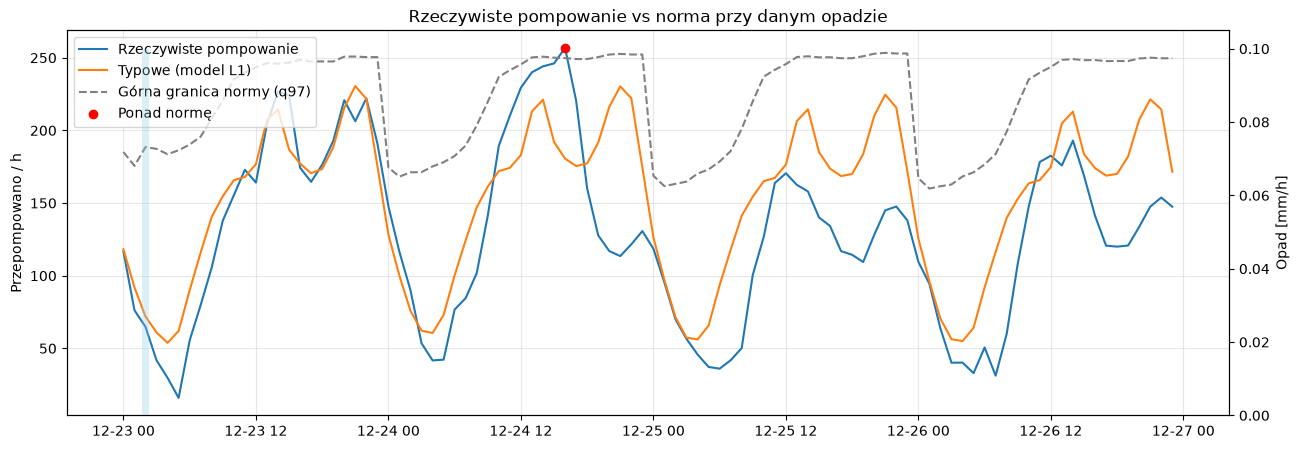

In [13]:
results_val = pd.DataFrame({
    "rzeczywiste": y_test,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_test["opad_0h"],
    "opad_6h": X_test["opad_6h"],
}, index=y_test.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2024-12-23":"2024-12-26"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [14]:
# Alarm, gdy rzeczywiste pompowanie przekracza Q97
results_val["alarm"] = results_val["anomaly"]

# Nadwyżka względem typowej prognozy pogodowej
results_val["nadwyzka"] = (
    results_val["rzeczywiste"] - results_val["prognoza"]
).clip(lower=0)

print("Liczba godzin alarmowych:", results_val["alarm"].sum())

print(
    "Suma nadwyżek w godzinach alarmowych:",
    round(results_val.loc[results_val["alarm"], "nadwyzka"].sum(), 2)
)

Liczba godzin alarmowych: 30
Suma nadwyżek w godzinach alarmowych: 2495.17


In [15]:
anomalie = results_val[results_val["alarm"]].copy()

#kiedy wystąpiły alarmy, jaka była nadwyżka i czy padało
display(anomalie[["rzeczywiste", "prognoza", "q97", "nadwyzka", "ponad_q97", "opad", "opad_6h"]])

,rzeczywiste,prognoza,q97,nadwyzka,ponad_q97,opad,opad_6h
Data_czas,,,,,,,
2024-10-06 11:00:00+01:00,274.3,188.030471,241.811874,86.269529,32.488126,0.0,0.0
2024-10-07 14:00:00+01:00,252.6,209.724166,239.921783,42.875834,12.678217,0.0,0.0
2024-10-08 14:00:00+01:00,247.4,216.260902,242.846535,31.139098,4.553465,0.0,0.0
2024-10-10 10:00:00+01:00,338.7,164.592352,228.666694,174.107648,110.033306,0.0,0.0
2024-10-12 12:00:00+01:00,252.0,215.590155,250.168739,36.409845,1.831261,0.0,0.0
2024-10-14 08:00:00+01:00,251.2,143.018466,192.354898,108.181534,58.845102,0.0,0.0
2024-10-18 14:00:00+01:00,245.0,219.301245,241.914144,25.698755,3.085856,0.0,0.0
2024-10-22 16:00:00+01:00,291.3,164.514529,242.926294,126.785471,48.373706,0.0,0.0
2024-10-31 00:00:00+01:00,165.5,88.064162,152.180517,77.435838,13.319483,0.0,0.0


In [16]:
from sklearn.metrics import mean_absolute_error
# Ewaluacja na zbiorze testowym
y_pred_test = cb_median.predict(X_test)
q_test = cb_q97.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred_test)
odsetek_test = (y_test > q_test).mean() * 100

print("MAE TEST:", round(mae_test, 2))
prof = y_train.groupby(y_train.index.hour).median()
base_test = prof.reindex(y_test.index.hour).values
print("MAE baseline:", round(mean_absolute_error(y_test, base_test), 2))
print("Przekroczenia Q97 TEST:", round(odsetek_test, 2), "%")
print("Liczba alarmów TEST:", int((y_test > q_test).sum()))


MAE TEST: 26.67
MAE baseline: 25.63
Przekroczenia Q97 TEST: 1.46 %
Liczba alarmów TEST: 30


In [17]:
#SHAP
import os
from SHAP import generate_shap_from_tree

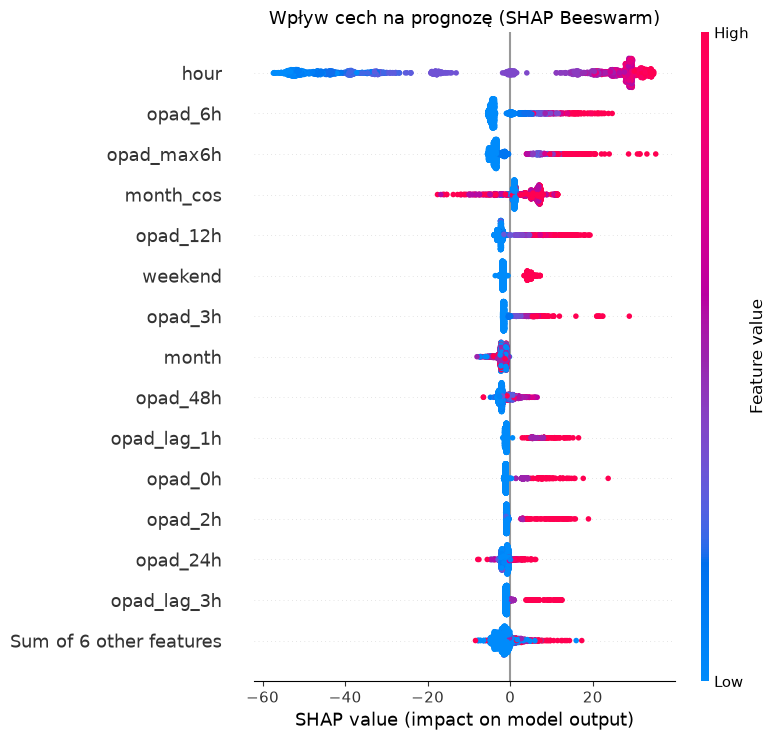

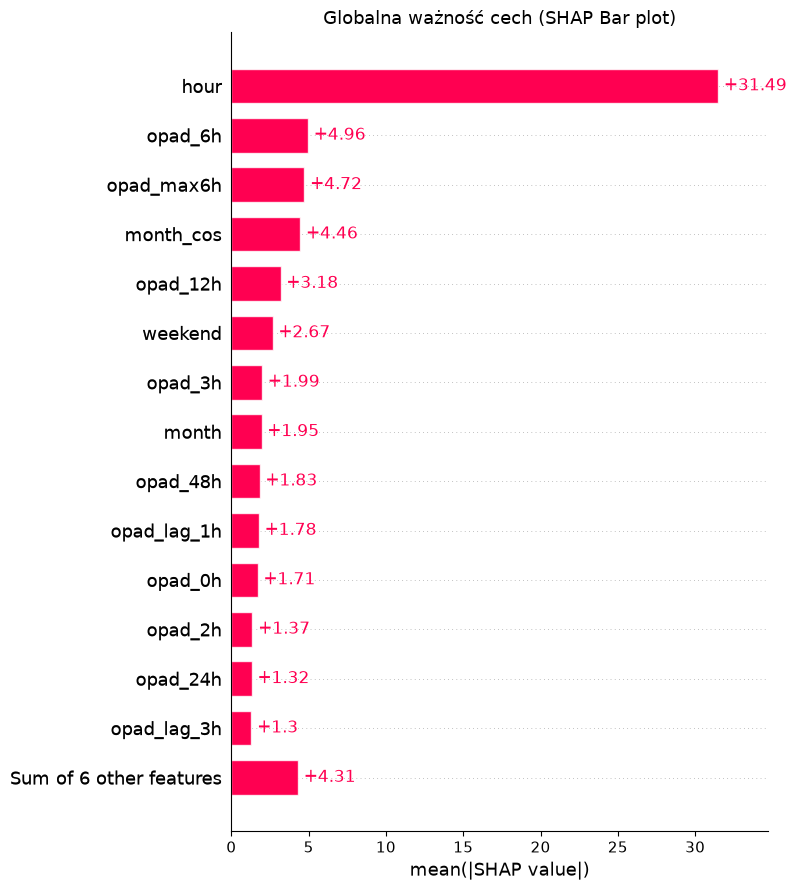

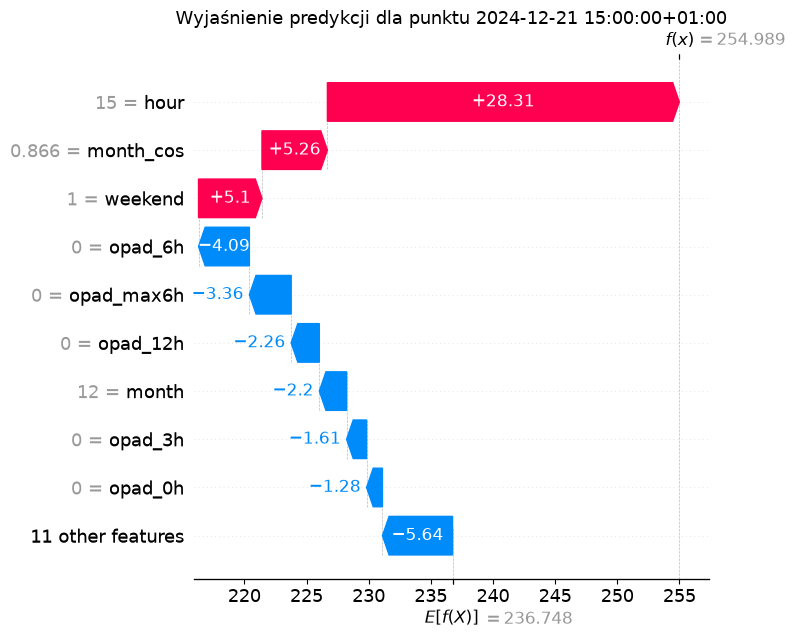

In [18]:
generate_shap_from_tree(cb_q97,X_test,date_with_time="2024-12-21 15:00:00")

# OPTYMALIZACJA OPTUNA

In [19]:
import numpy as np
import optuna
from lightgbm import LGBMRegressor, early_stopping, log_evaluation

train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

import numpy as np
import optuna
from catboost import CatBoostRegressor

# STROJENIE MODELU MEDIANOWEGO (cb_median)
def objective_median(trial):
    params = {
        'loss_function': 'MAE',
        'eval_metric': 'MAE',
        'iterations': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 5.0),
        'task_type': 'CPU',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params, early_stopping_rounds=40)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

    preds = model.predict(X_val)
    mae = np.mean(np.abs(y_val - preds))
    return mae

study_median = optuna.create_study(direction="minimize")
study_median.optimize(objective_median, n_trials=40)
print("Najlepsze parametry dla Median:", study_median.best_params)


# STROJENIE MODELU KWANTYLOWEGO (cb_q97)
def pinball_loss(y_true, y_pred, alpha=0.97):
    err = y_true - y_pred
    return np.mean(np.maximum(alpha * err, (alpha - 1.0) * err))

def objective_q97(trial):
    params = {
        'loss_function': 'Quantile:alpha=0.97',
        'eval_metric': 'Quantile:alpha=0.97',
        'iterations': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 5.0),
        'task_type': 'CPU',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params, early_stopping_rounds=40)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

    q_preds = model.predict(X_val)

    #Błąd Pinball
    loss = pinball_loss(y_val, q_preds, alpha=0.97)

    #Kara za uciekanie od Coverage = 97%
    empirical_coverage = np.mean(y_val <= q_preds)
    coverage_penalty = np.abs(empirical_coverage - 0.97) * 5.0

    return loss + coverage_penalty

study_q97 = optuna.create_study(direction="minimize")
study_q97.optimize(objective_q97, n_trials=40)
print("Najlepsze parametry dla Q97:", study_q97.best_params)

[I 2026-10-27 21:41:16,070] A new study created in memory with name: no-name-a00825a6-d8c5-485a-a04c-63c95e71599b
[I 2026-10-27 21:41:16,786] Trial 0 finished with value: 24.874915308013875 and parameters: {'learning_rate': 0.022131422824802183, 'depth': 4, 'l2_leaf_reg': 3.4037902610735538, 'random_strength': 3.5759273679258983}. Best is trial 0 with value: 24.874915308013875.
[I 2026-10-27 21:41:17,241] Trial 1 finished with value: 25.55840137724248 and parameters: {'learning_rate': 0.03491439572613217, 'depth': 4, 'l2_leaf_reg': 18.793542094668314, 'random_strength': 3.5523230781778223}. Best is trial 0 with value: 24.874915308013875.
[I 2026-10-27 21:41:17,645] Trial 2 finished with value: 26.55729272204181 and parameters: {'learning_rate': 0.01970663337904175, 'depth': 6, 'l2_leaf_reg': 9.962777700116073, 'random_strength': 3.797930090291739}. Best is trial 0 with value: 24.874915308013875.
[I 2026-10-27 21:41:18,109] Trial 3 finished with value: 25.099939698812335 and parameters:

Najlepsze parametry dla Median: {'learning_rate': 0.0282913085556902, 'depth': 7, 'l2_leaf_reg': 5.707603051834794, 'random_strength': 0.07334046663692162}


[I 2026-10-27 21:41:40,194] Trial 0 finished with value: 2.921866584000209 and parameters: {'learning_rate': 0.010160158715849547, 'depth': 8, 'l2_leaf_reg': 5.332587104417457, 'random_strength': 2.384100344161056}. Best is trial 0 with value: 2.921866584000209.
[I 2026-10-27 21:41:42,002] Trial 1 finished with value: 2.965464229220596 and parameters: {'learning_rate': 0.011687259418541473, 'depth': 7, 'l2_leaf_reg': 9.477837782226276, 'random_strength': 1.8325671871023819}. Best is trial 0 with value: 2.921866584000209.
[I 2026-10-27 21:41:42,994] Trial 2 finished with value: 3.0897605185942316 and parameters: {'learning_rate': 0.016868087363290853, 'depth': 6, 'l2_leaf_reg': 2.866435697821507, 'random_strength': 3.14905619588383}. Best is trial 0 with value: 2.921866584000209.
[I 2026-10-27 21:41:43,634] Trial 3 finished with value: 3.0463674542359853 and parameters: {'learning_rate': 0.0687171466270091, 'depth': 8, 'l2_leaf_reg': 10.033200626320124, 'random_strength': 3.391415203232

Najlepsze parametry dla Q97: {'learning_rate': 0.05883790128236064, 'depth': 5, 'l2_leaf_reg': 19.631654919370728, 'random_strength': 0.8082472986982736}


In [20]:
print("Najlepszy wynik median (MAE):", study_median.best_value)
print("Najlepsze parametry median:", study_median.best_params)

print("Najlepszy wynik q97 (MAE):", study_q97.best_value)
print("Najlepsze parametry q97:", study_q97.best_params)

Najlepszy wynik median (MAE): 22.783066596502454
Najlepsze parametry median: {'learning_rate': 0.0282913085556902, 'depth': 7, 'l2_leaf_reg': 5.707603051834794, 'random_strength': 0.07334046663692162}
Najlepszy wynik q97 (MAE): 2.8511273756858193
Najlepsze parametry q97: {'learning_rate': 0.05883790128236064, 'depth': 5, 'l2_leaf_reg': 19.631654919370728, 'random_strength': 0.8082472986982736}


In [21]:
# CATBOOST
from catboost import CatBoostRegressor


check_median = CatBoostRegressor(
    **study_median.best_params,
    loss_function="MAE",
    eval_metric="MAE",
    iterations=2500,
    early_stopping_rounds=50,
    task_type="CPU",
    thread_count=-1,
    random_seed=42,
    verbose=100
)
check_median.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True
)


best_trees = check_median.get_best_iteration()
print(f"Optymalna liczba iteracji: {best_trees}")

0:	learn: 54.1391663	test: 46.1273038	best: 46.1273038 (0)	total: 2.07ms	remaining: 5.18s
100:	learn: 25.8355006	test: 24.2021970	best: 24.1950504 (99)	total: 174ms	remaining: 4.13s
200:	learn: 22.0002415	test: 23.2776811	best: 23.2559861 (193)	total: 348ms	remaining: 3.98s
300:	learn: 20.1090537	test: 22.9592955	best: 22.7830653 (262)	total: 529ms	remaining: 3.87s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 22.78306531
bestIteration = 262

Shrink model to first 263 iterations.
Optymalna liczba iteracji: 262


In [22]:
from catboost import CatBoostRegressor


check_q97 = CatBoostRegressor(
    **study_q97.best_params,
    loss_function="Quantile:alpha=0.97",
    eval_metric="Quantile:alpha=0.97",
    iterations=2500,
    early_stopping_rounds=50,
    task_type="CPU",
    thread_count=-1,
    random_seed=42,
    verbose=0
)

check_q97.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True)

best_trees_q97 = check_q97.get_best_iteration()
print(f"Optymalna liczba iteracji dla q97 to: {best_trees_q97}")

Optymalna liczba iteracji dla q97 to: 284
